# asthma: drug rankings with and without the connectivity-score Monte Carlo p-value filter

Case study `asthma_GSE152004` (GSE152004). Each connectivity score (CS) in the CS runs of this case study carries a Monte Carlo
p-value (`cs_p_value`). This notebook drops the CS values that are not significant against random gene sets and
compares the resulting drug rankings with the unfiltered ones, in the TSR route (one CS per drug) and in the
per-instance route (one CS per LINCS instance, summarised per compound by sRGES, wsRGES and best).
Sign convention for every score: more negative = stronger predicted reversal of the disease signature.

## Definitions

Terms as computed by the code. Scores are dimensionless ("CS units").

| Term | What it is | Where computed |
|---|---|---|
| **CS** (connectivity score, `bin_chen` method) | Score of one drug signature against the disease signature; more negative = the drug signature reverses the disease signature more strongly. CS units. | `src/connectivity_score.py` |
| **CS p-value** (`cs_p_value`) | Fraction of 1000 random gene sets (same numbers of up- and down-regulated genes, positions drawn without replacement among the reference genes) whose \|CS\| is greater than or equal to the observed \|CS\|. No pseudocount: the value 0 occurs, and the sign of the CS is not used. Resolution 0.001. | `montecarlo_connectivity`, `src/connectivity_score.py` |
| **p'** | (k + 1) / (1000 + 1) with k = `cs_p_value` x 1000; smallest value 0.000999. | `cs_pvalue_filter.flag` |
| **p_adj** | Benjamini-Hochberg adjustment of p' over the rows of one CS run. A CS run is one execution of the CS on one disease signature and one set of drug signatures. | `cs_pvalue_filter.bh` |
| **BH filter** (`bh05`, primary) | Keeps the rows with p_adj <= 0.05. | `cs_pvalue_filter.flag` |
| **Raw filter** (`raw05`, secondary) | Keeps the rows with p' <= 0.05, without multiple-testing adjustment. | `cs_pvalue_filter.flag` |
| **p_adj of the rows at p = 0** | Rows with `cs_p_value` = 0 share the smallest p'; in a run of m rows of which n0 are at p = 0, their p_adj is at most (1 / 1001) x m / n0 (upper bound; the BH step-up takes the minimum over later ranks, so the value can be lower). The bound is <= 0.05 when n0 >= m / 50. | `cs_pvalue_filter.run_stats` |
| **Frozen-offset variant** (`bh05_frozen`) | BH filter, with the surviving instances scored with the dose/time offset table of the unfiltered instances instead of one rebuilt from the survivors; separates the effect of selecting instances from the effect of a changed correction. | `cs_pvalue_filter.frozen_offsets` |
| **Cell-line weight mass lost** | Instance level: 1 - (sum of the weights of the kept used instances) / (sum of the weights of all used instances), over used instances on weighted lines; line level: the same ratio over the weighted lines that keep at least one used instance. Used instance = dose > 0 at 6 or 24 h. | `cs_pvalue_filter.line_stats` |
| **Instance** | One LINCS L1000 level-5 profile: one compound, one cell line, one dose (uM), one time (6 or 24 h). | step `srges` |
| **Configuration** | Which signatures enter the CS: `DEG` (gene-level log2 fold changes), `DEG_LM` (the same restricted to the 978 landmark genes; TSR route only), `mith` (MITHrIL gene perturbations, about 15,800 features), `mith_LM` (MITHrIL perturbations restricted to the landmark genes), `mith_pw` (MITHrIL pathway perturbations). | `per_drug_scores.CONFIGS`, `known_drugs.TSR_CONFIGS` |
| **TSR route**, `<config>_TSR` | One CS per drug on drug signatures collapsed before the CS (drug input `all`, pooled `6h_24h` rows); the ranking score is the CS. After the filter, the drugs with a non-significant CS leave the ranking. | `known_drugs.tsr_rankings` |
| **Per-instance route** | One CS per instance (71 cell lines x configuration); one score per compound after the CS. After the filter, the non-significant instances are dropped and the scores are recomputed from the surviving instances. | `per_drug_scores.collapse` |
| **sRGES** (`<config>_sRGES`) | Per compound: mean over its instances (dose > 0, 6 or 24 h, all cell lines) of the dose/time-adjusted CS (assignment `corrected`; the offset table is rebuilt from the instances present). CS units. | `sRGES.compute_sRGES` |
| **wsRGES** (`<config>_wsRGES`) | The same mean with each instance multiplied by its cell-line weight divided by the largest weight; instances on lines without a weight are left out. CS units. | `sRGES.compute_sRGES` |
| **best** (`<config>_best`) | Per compound: the most negative CS among its instances (dose > 0, 6 or 24 h). CS units. | `per_drug_scores.collapse` |
| **topMed** (`_sRGES_topMed`, `_wsRGES_topMed`, `_sRGES_topQ3`, `_wsRGES_topQ3`) | sRGES / wsRGES restricted to the cell lines above the median (or third-quartile) cutoff of `top_cell_lines`. | `per_drug_scores.collapse` |
| **Ranking** | `<config>_<score>`: compounds sorted by ascending score. Names are normalised to lower case, alphanumerics only (`drug_key`). | `known_drugs` |
| **Percentile** | `rank(pct=True)` x 100 of the score within the ranking's own universe, ascending: 0-100, low = stronger predicted reversal. | `known_drugs.add_ranks` |
| **Universe** | The compounds a ranking scores. Filtering shrinks it, so the percentile of a compound changes even when its score does not. | |
| **Shared universe** | The compounds scored by both rankings that are compared. | `cs_pvalue_filter.compare_rankings` |

In [1]:
import sys, os, warnings, logging
from pathlib import Path
warnings.filterwarnings('ignore')
logging.disable(logging.WARNING)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

SLUG = 'asthma_GSE152004'
ROOT = Path(os.getcwd()).resolve()
while not (ROOT / 'connectivity_score' / 'input').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import conf
import lfs_style
import case_study_pipeline as cp
from case_study import cs_pvalue_filter as pf
from case_study import known_drugs as kd
from case_study.common import config_colour

lfs_style.apply()
cc = cp.load_case_conf(SLUG)
OUT, IMG = cc.P.oout_dir, cc.P.img_dir
IMG.mkdir(parents=True, exist_ok=True)
REL = '../imgs/case_studies/' + SLUG      # image path relative to this notebook
TOL = 1e-12
assert conf.CS_METHOD == 'bin_chen' and conf.srges_diff_mode == 'corrected'

res = pf.compute(cc)
tsr_names = [n for n in res['rk']['none'] if n.endswith('_TSR')]
pi_names = [n for n in res['rk']['none'] if not n.endswith('_TSR')]
display(Markdown(f"Computed from the CS runs of `{SLUG}`: {len(tsr_names)} TSR rankings and {len(pi_names)} per-instance rankings "
                 f"(srges_diff_mode = `{conf.srges_diff_mode}`, N = {pf.N_ITER} random gene sets per CS, alpha = {pf.ALPHA})."))

Computed from the CS runs of `asthma_GSE152004`: 5 TSR rankings and 28 per-instance rankings (srges_diff_mode = `corrected`, N = 1000 random gene sets per CS, alpha = 0.05).

## 1. Filter

For every CS run the p-value `cs_p_value` is converted to p' = (k + 1) / 1001 (k = `cs_p_value` x 1000, so that p' > 0),
adjusted by Benjamini-Hochberg over all rows of that run, and a row is kept when p_adj <= 0.05 (primary filter, `bh05`);
the secondary filter keeps p' <= 0.05 (`raw05`). The filter uses only the p-value, not the sign of the CS, so
significantly positive CS (drug signatures that resemble the disease signature) are kept as well.

- **TSR route.** Input: the `6h_24h` rows of the drug-input-`all` CS run of each configuration. Operation: BH over those
  rows; drugs that do not pass are dropped. Output: a ranking of the surviving drugs, scores unchanged.
- **Per-instance route.** Input: the CS run of each (configuration, cell line) pair listed in
  `asthma_GSE152004_srges_cs_runs_used.tsv` (the BH adjustment is over the instances of that run). Operation: the instances that
  do not pass are dropped; `per_drug_scores.collapse` (the step-`srges` function) recomputes sRGES, wsRGES, best and
  the top-line variants from the surviving instances, with the dose/time offset table rebuilt from them. A compound with
  no surviving instance leaves the ranking; a collapse variant left with no instance at all gives an empty ranking.
  Output: rankings of the surviving compounds. A second variant (`bh05_frozen`) scores the surviving instances with the
  dose/time offset table of the unfiltered instances; its rankings are compared with those of the rebuilt-offset variant.
- **Drug keys.** Rows whose names normalise to the same `drug_key` are filtered individually and the surviving rows averaged.

## 2. p-value distribution and resolution per configuration

In [2]:
rs = res['run_stats'].copy()
agg = (rs.groupby(['route', 'config'], sort=False)
         .agg(n_runs=('cs_run_id', 'size'), n_rows=('n_rows', 'sum'), n_p0=('n_p0', 'sum'),
              n_keep_bh05=('n_keep_bh05', 'sum'), n_keep_raw05=('n_keep_raw05', 'sum'),
              median_p_adj_at_p0=('p_adj_at_p0', 'median'), median_p_adj_p0_upper_bound=('p_adj_p0_upper_bound', 'median'),
              n_runs_no_row_kept_bh05=('n_keep_bh05', lambda s: int((s == 0).sum())))
         .reset_index())
agg['frac_p0'] = agg['n_p0'] / agg['n_rows']
agg['frac_kept_bh05'] = agg['n_keep_bh05'] / agg['n_rows']
agg['frac_kept_raw05'] = agg['n_keep_raw05'] / agg['n_rows']
agg = agg[['route', 'config', 'n_runs', 'n_rows', 'frac_p0', 'median_p_adj_at_p0', 'median_p_adj_p0_upper_bound',
           'n_runs_no_row_kept_bh05', 'frac_kept_bh05', 'frac_kept_raw05']]
agg.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_resolution.tsv', sep='\t', index=False)
rs.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_runs.tsv', sep='\t', index=False)
display(Markdown(
    f"**Table 1.** Monte Carlo p-values of the CS runs, per route and configuration (`{SLUG}_cs_pvalue_filter_resolution.tsv`; "
    f"one row per route x configuration; per-run values in `{SLUG}_cs_pvalue_filter_runs.tsv`). "
    "`n_runs`: CS runs (per-instance: one per cell line; TSR: one run); `n_rows`: CS values (instances, or drugs at `6h_24h`); "
    "`frac_p0`: fraction of rows with `cs_p_value` = 0 (fraction 0-1); `median_p_adj_at_p0`: median over runs of the p_adj of the rows at p = 0, and `median_p_adj_p0_upper_bound` of its upper bound (1/1001) x m / n0 "
    "(unitless, 0-1; empty when a run has no row at p = 0); `n_runs_no_row_kept_bh05`: runs in which the BH filter keeps "
    "no row; `frac_kept_bh05`, `frac_kept_raw05`: fraction of rows kept (0-1).\n\n" + pf.md_table(agg, 3)))

**Table 1.** Monte Carlo p-values of the CS runs, per route and configuration (`asthma_GSE152004_cs_pvalue_filter_resolution.tsv`; one row per route x configuration; per-run values in `asthma_GSE152004_cs_pvalue_filter_runs.tsv`). `n_runs`: CS runs (per-instance: one per cell line; TSR: one run); `n_rows`: CS values (instances, or drugs at `6h_24h`); `frac_p0`: fraction of rows with `cs_p_value` = 0 (fraction 0-1); `median_p_adj_at_p0`: median over runs of the p_adj of the rows at p = 0, and `median_p_adj_p0_upper_bound` of its upper bound (1/1001) x m / n0 (unitless, 0-1; empty when a run has no row at p = 0); `n_runs_no_row_kept_bh05`: runs in which the BH filter keeps no row; `frac_kept_bh05`, `frac_kept_raw05`: fraction of rows kept (0-1).

| route | config | n_runs | n_rows | frac_p0 | median_p_adj_at_p0 | median_p_adj_p0_upper_bound | n_runs_no_row_kept_bh05 | frac_kept_bh05 | frac_kept_raw05 |
|---|---|---|---|---|---|---|---|---|---|
| tsr | DEG | 1 | 3222 | 0.535 | 0.002 | 0.002 | 0 | 0.681 | 0.698 |
| tsr | DEG_LM | 1 | 3222 | 0.016 | 0.063 | 0.063 | 1 | 0.000 | 0.178 |
| tsr | mith | 1 | 3223 | 0.994 | 0.001 | 0.001 | 0 | 0.998 | 0.998 |
| tsr | mith_LM | 1 | 3223 | 0.025 | 0.039 | 0.039 | 0 | 0.041 | 0.232 |
| tsr | mith_pw | 1 | 3223 | 0.765 | 0.001 | 0.001 | 0 | 0.982 | 0.982 |
| per_instance | DEG | 71 | 66511 | 0.054 | 0.023 | 0.023 | 12 | 0.128 | 0.297 |
| per_instance | mith | 71 | 66511 | 0.911 | 0.001 | 0.001 | 0 | 0.998 | 0.998 |
| per_instance | mith_LM | 71 | 66511 | 0.020 | 0.053 | 0.054 | 45 | 0.022 | 0.185 |
| per_instance | mith_pw | 71 | 66511 | 0.791 | 0.001 | 0.001 | 0 | 0.972 | 0.973 |

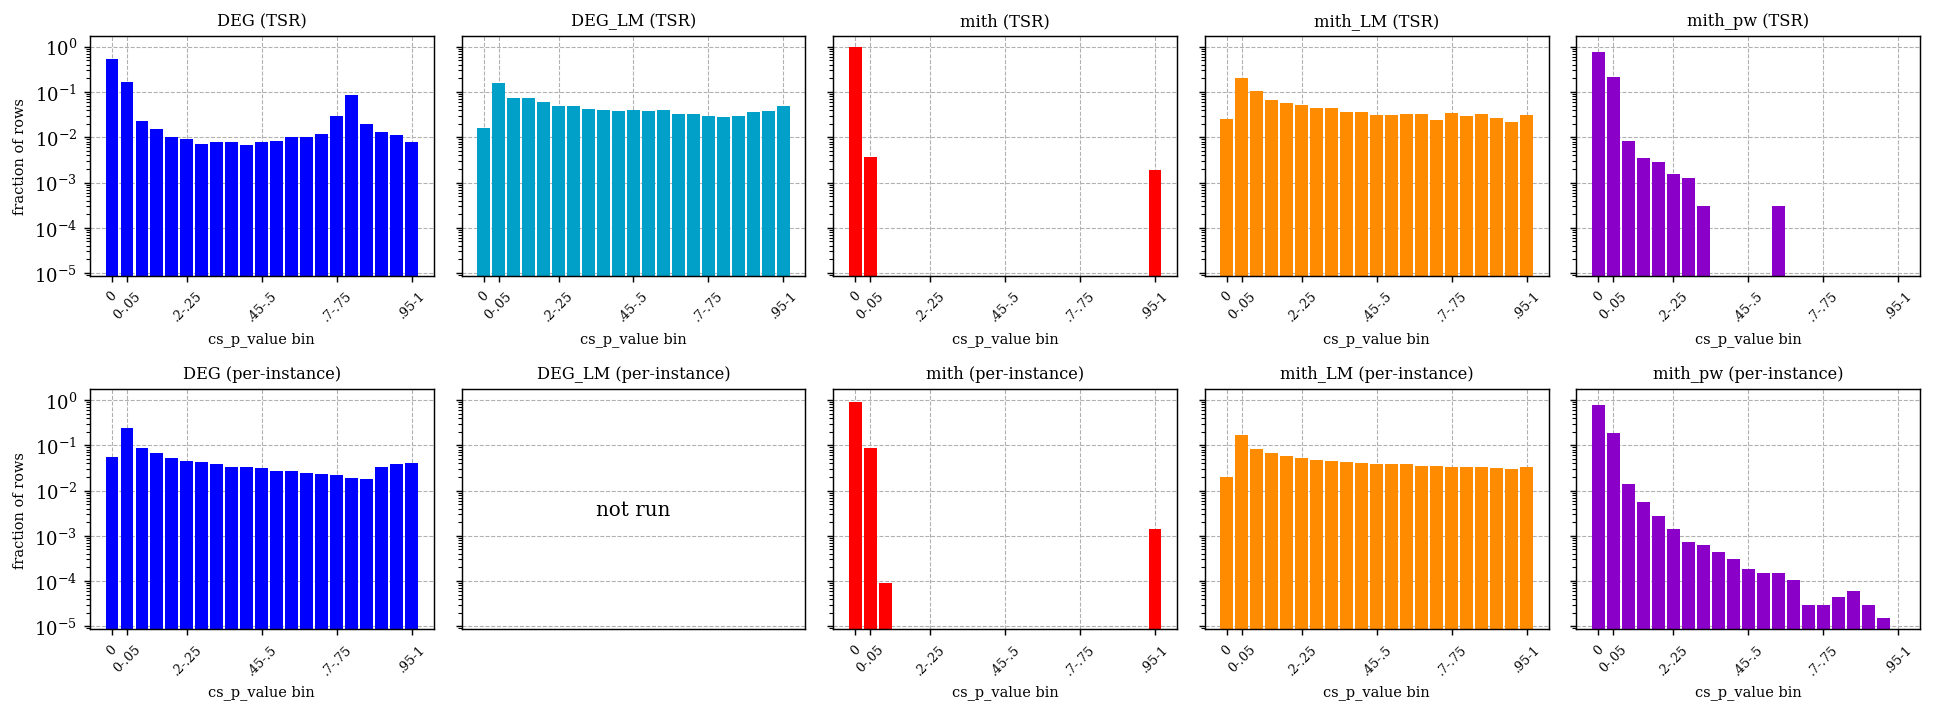

![p-value distribution](../imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_pvalue_distribution.png)

**Figure 1.** Distribution of `cs_p_value` per configuration; top row TSR drugs (`6h_24h` rows), bottom row per-instance CS pooled over the cell lines. Bars: fraction of rows (0-1, logarithmic axis) at p = 0 (first bar) and in 20 bins of width 0.05 (0 < p <= 0.05, ..., 0.95 < p <= 1).

In [3]:
cfgs_all = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']
edges = np.r_[-1e-9, 0.0005, np.arange(0.05, 1.0001, 0.05)]
labels = ['0'] + [f'{a:.2f}-{b:.2f}' for a, b in zip(np.arange(0, 1, 0.05), np.arange(0.05, 1.0001, 0.05))]
fig, axes = plt.subplots(2, 5, figsize=(15, 5.6), sharey=True)
for i, route in enumerate(['tsr', 'per_instance']):
    for j, c in enumerate(cfgs_all):
        ax = axes[i, j]
        p = res['pvals'].get((route, c))
        ax.set_title(f"{c} ({'TSR' if route == 'tsr' else 'per-instance'})", fontsize=9)
        if p is None:
            ax.text(.5, .5, 'not run', ha='center', va='center', transform=ax.transAxes); ax.set_xticks([]); ax.set_yticks([]); continue
        cnt = np.histogram(p, bins=edges)[0]
        ax.bar(range(len(cnt)), cnt / len(p), color=config_colour(c), width=.85)
        ax.set_yscale('log'); ax.set_xticks([0, 1, 5, 10, 15, 20]); ax.set_xticklabels(['0', '0-.05', '.2-.25', '.45-.5', '.7-.75', '.95-1'], fontsize=7, rotation=45)
        ax.set_xlabel('cs_p_value bin', fontsize=8)
        if j == 0: ax.set_ylabel('fraction of rows', fontsize=8)
plt.tight_layout()
f = IMG / f'{SLUG}_cs_pvalue_filter_pvalue_distribution.png'
fig.savefig(f, dpi=130); plt.close(fig)
display(Image(filename=str(f)))   # inline in the notebook; the Markdown link below serves the exported report
display(Markdown(f"![p-value distribution]({REL}/{f.name})\n\n**Figure 1.** Distribution of `cs_p_value` per configuration; top row TSR drugs (`6h_24h` rows), "
                 "bottom row per-instance CS pooled over the cell lines. Bars: fraction of rows (0-1, logarithmic axis) at p = 0 (first bar) and in "
                 "20 bins of width 0.05 (0 < p <= 0.05, ..., 0.95 < p <= 1)."))

In [4]:
sat = agg[agg['frac_p0'] >= 0.5]
unsat = agg[agg['frac_p0'] < 0.5]
txt = ["**Reading of Table 1.**"]
txt.append("Runs in which at least half of the rows have `cs_p_value` = 0: " + (", ".join(f"{r.route} {r.config} (fraction at p = 0: {r.frac_p0:.3f}; fraction kept by BH: {r.frac_kept_bh05:.3f})" for r in sat.itertuples()) or "none") + ".")
txt.append("Runs in which fewer than half of the rows have `cs_p_value` = 0: " + (", ".join(f"{r.route} {r.config} (fraction at p = 0: {r.frac_p0:.3f}; kept by BH: {r.frac_kept_bh05:.3f}; by the raw filter: {r.frac_kept_raw05:.3f})" for r in unsat.itertuples()) or "none") + ".")
txt.append("In a run where `cs_p_value` is 0 for every row, p_adj is the same small number (1/1001 = 0.000999) for every row, so both filters keep every row and the filter does not discriminate between rows; in a run where fewer than 2% of the rows are at p = 0 the upper bound (1/1001) x m / n0 exceeds 0.05 (the bound is not the minimum, so rows at p = 0 can still pass through later ranks).")
display(Markdown("\n\n".join(txt)))

**Reading of Table 1.**

Runs in which at least half of the rows have `cs_p_value` = 0: tsr DEG (fraction at p = 0: 0.535; fraction kept by BH: 0.681), tsr mith (fraction at p = 0: 0.994; fraction kept by BH: 0.998), tsr mith_pw (fraction at p = 0: 0.765; fraction kept by BH: 0.982), per_instance mith (fraction at p = 0: 0.911; fraction kept by BH: 0.998), per_instance mith_pw (fraction at p = 0: 0.791; fraction kept by BH: 0.972).

Runs in which fewer than half of the rows have `cs_p_value` = 0: tsr DEG_LM (fraction at p = 0: 0.016; kept by BH: 0.000; by the raw filter: 0.178), tsr mith_LM (fraction at p = 0: 0.025; kept by BH: 0.041; by the raw filter: 0.232), per_instance DEG (fraction at p = 0: 0.054; kept by BH: 0.128; by the raw filter: 0.297), per_instance mith_LM (fraction at p = 0: 0.020; kept by BH: 0.022; by the raw filter: 0.185).

In a run where `cs_p_value` is 0 for every row, p_adj is the same small number (1/1001 = 0.000999) for every row, so both filters keep every row and the filter does not discriminate between rows; in a run where fewer than 2% of the rows are at p = 0 the upper bound (1/1001) x m / n0 exceeds 0.05 (the bound is not the minimum, so rows at p = 0 can still pass through later ranks).

## 3. Fraction kept, universe size, agreement and top-20 overlap

In [5]:
cmp = {m: pf.compare_rankings(res['rk']['none'], res['rk'][m]) for m in ('bh05', 'raw05', 'bh05f')}
MODE_NAME = {'bh05': 'bh05', 'raw05': 'raw05', 'bh05f': 'bh05_frozen'}
summ = pd.concat([c.assign(filter=MODE_NAME[m]) for m, c in cmp.items()], ignore_index=True)
summ.insert(0, 'config', summ['ranking'].map(lambda n: res['meta'][n][0]))
summ.insert(1, 'route', np.where(summ['ranking'].str.endswith('_TSR'), 'tsr', 'per_instance'))
summ = summ[['filter', 'ranking', 'config', 'route', 'n_before', 'n_after', 'frac_kept', 'n_shared', 'spearman',
             f'top{pf.TOP}_overlap', f'top{pf.TOP}_overlap_shared']]
summ.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_summary.tsv', sep='\t', index=False)
ik = res['inst_kept'].pivot(index='config', columns='mode', values='n_kept')
ik['frac_kept_bh05'] = ik['bh05'] / ik['none']; ik['frac_kept_raw05'] = ik['raw05'] / ik['none']
ik = ik.rename(columns={'none': 'n_instances'}).reset_index()[['config', 'n_instances', 'bh05', 'raw05', 'frac_kept_bh05', 'frac_kept_raw05']]
ik = ik.rename(columns={'bh05': 'n_kept_bh05', 'raw05': 'n_kept_raw05'})
ik.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_instances_kept.tsv', sep='\t', index=False)
display(Markdown(f"**Table 2.** Per-instance route: instances (all dose and time points of the CS runs) kept by each filter, per configuration "
                 f"(`{SLUG}_cs_pvalue_filter_instances_kept.tsv`; fractions 0-1).\n\n" + pf.md_table(ik, 3)))

**Table 2.** Per-instance route: instances (all dose and time points of the CS runs) kept by each filter, per configuration (`asthma_GSE152004_cs_pvalue_filter_instances_kept.tsv`; fractions 0-1).

| config | n_instances | n_kept_bh05 | n_kept_raw05 | frac_kept_bh05 | frac_kept_raw05 |
|---|---|---|---|---|---|
| DEG | 66511 | 8482 | 19758 | 0.128 | 0.297 |
| mith | 66511 | 66411 | 66411 | 0.998 | 0.998 |
| mith_LM | 66511 | 1458 | 12289 | 0.022 | 0.185 |
| mith_pw | 66511 | 64675 | 64737 | 0.972 | 0.973 |

In [6]:
ls = res['line_stats']
tr = []
for n, r in res['tsr_rows'].items():
    for m in ('bh05', 'raw05'):
        kk = r[r[f'keep_{m}']]
        tr.append({'route': 'tsr', 'config': n[:-4], 'filter': m, 'n_rows': len(r), 'n_kept': len(kk), 'n_kept_neg': int((kk['connectivity_score'] < 0).sum()),
                   'n_kept_pos': int((kk['connectivity_score'] > 0).sum())})
sg = pd.concat([pd.DataFrame(tr), ls.assign(route='per_instance', filter=ls['mode'], n_rows=res['inst_kept'].query("mode == 'none'").set_index('config')['n_instances'].reindex(ls['config']).values)
                [['route', 'config', 'filter', 'n_rows', 'n_kept', 'n_kept_neg', 'n_kept_pos']]], ignore_index=True)
sg['frac_kept_neg'] = sg['n_kept_neg'] / sg['n_kept']
sg['frac_kept_pos'] = sg['n_kept_pos'] / sg['n_kept']
sg.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_sign_split.tsv', sep='\t', index=False)
display(Markdown(f"**Table 2b.** Sign of the CS values kept by each filter (`{SLUG}_cs_pvalue_filter_sign_split.tsv`; one row per route, configuration and filter). `n_rows`: CS values of the run(s) "
                 "(TSR: `6h_24h` rows; per-instance: all instances); `n_kept_neg`, `n_kept_pos`: kept values with CS < 0 (reversal) and CS > 0 (count); `frac_kept_neg`, `frac_kept_pos`: their share of the kept values (0-1). "
                 "The p-value is two-sided in |CS|, so the filter keeps significantly positive CS as well; the stored p-value has no one-sided counterpart, "
                 "so the table gives the counts of kept negative CS and no new Monte Carlo was run.\n\n" + pf.md_table(sg, 3)))
cl = ls[ls['mode'] == 'bh05'].copy()
med = {}
for c in cl['config']:
    a_, b_ = res['rk']['none'][f'{c}_sRGES'], res['rk']['bh05'].get(f'{c}_sRGES')
    med[c] = (a_['n_cell_lines'].median(), np.nan if b_ is None or len(b_) == 0 else b_['n_cell_lines'].median())
cl['median_n_cell_lines_per_compound_before'] = cl['config'].map(lambda c: med[c][0])
cl['median_n_cell_lines_per_compound_after'] = cl['config'].map(lambda c: med[c][1])
cl = cl[['config', 'n_lines_used', 'n_lines_kept', 'n_weighted_lines', 'n_weighted_lines_kept', 'frac_line_weight_lost', 'frac_instance_weight_lost',
         'median_n_cell_lines_per_compound_before', 'median_n_cell_lines_per_compound_after']]
cl.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_cell_lines.tsv', sep='\t', index=False)
display(Markdown(f"**Table 2c.** BH filter, per-instance route: cell-line retention per configuration (`{SLUG}_cs_pvalue_filter_cell_lines.tsv`). `n_lines_used`, `n_lines_kept`: cell lines with at least one instance used by sRGES "
                 "(dose > 0 at 6 or 24 h) before and after filtering (count, of 71); `n_weighted_lines`, `n_weighted_lines_kept`: the same for lines with a cell-line weight (the lines wsRGES uses); "
                 "`frac_line_weight_lost`: share (0-1) of the summed weights of the weighted lines that keep no used instance; `frac_instance_weight_lost`: share (0-1) of the weight carried by the used instances on weighted lines "
                 "that is dropped; last two columns: median number of cell lines per compound in `<config>_sRGES` before and after.\n\n" + pf.md_table(cl, 3)))

**Table 2b.** Sign of the CS values kept by each filter (`asthma_GSE152004_cs_pvalue_filter_sign_split.tsv`; one row per route, configuration and filter). `n_rows`: CS values of the run(s) (TSR: `6h_24h` rows; per-instance: all instances); `n_kept_neg`, `n_kept_pos`: kept values with CS < 0 (reversal) and CS > 0 (count); `frac_kept_neg`, `frac_kept_pos`: their share of the kept values (0-1). The p-value is two-sided in |CS|, so the filter keeps significantly positive CS as well; the stored p-value has no one-sided counterpart, so the table gives the counts of kept negative CS and no new Monte Carlo was run.

| route | config | filter | n_rows | n_kept | n_kept_neg | n_kept_pos | frac_kept_neg | frac_kept_pos |
|---|---|---|---|---|---|---|---|---|
| tsr | DEG | bh05 | 3222 | 2195 | 1248 | 947 | 0.569 | 0.431 |
| tsr | DEG | raw05 | 3222 | 2249 | 1284 | 965 | 0.571 | 0.429 |
| tsr | DEG_LM | bh05 | 3222 | 0 | 0 | 0 |  |  |
| tsr | DEG_LM | raw05 | 3222 | 573 | 246 | 327 | 0.429 | 0.571 |
| tsr | mith | bh05 | 3223 | 3217 | 906 | 2311 | 0.282 | 0.718 |
| tsr | mith | raw05 | 3223 | 3217 | 906 | 2311 | 0.282 | 0.718 |
| tsr | mith_LM | bh05 | 3223 | 131 | 5 | 126 | 0.038 | 0.962 |
| tsr | mith_LM | raw05 | 3223 | 747 | 61 | 686 | 0.082 | 0.918 |
| tsr | mith_pw | bh05 | 3223 | 3165 | 2002 | 1163 | 0.633 | 0.367 |
| tsr | mith_pw | raw05 | 3223 | 3166 | 2003 | 1163 | 0.633 | 0.367 |
| per_instance | DEG | bh05 | 66511 | 8482 | 4792 | 3690 | 0.565 | 0.435 |
| per_instance | DEG | raw05 | 66511 | 19758 | 10966 | 8792 | 0.555 | 0.445 |
| per_instance | mith | bh05 | 66511 | 66411 | 23532 | 42879 | 0.354 | 0.646 |
| per_instance | mith | raw05 | 66511 | 66411 | 23532 | 42879 | 0.354 | 0.646 |
| per_instance | mith_LM | bh05 | 66511 | 1458 | 510 | 948 | 0.350 | 0.650 |
| per_instance | mith_LM | raw05 | 66511 | 12289 | 4555 | 7734 | 0.371 | 0.629 |
| per_instance | mith_pw | bh05 | 66511 | 64675 | 36504 | 28171 | 0.564 | 0.436 |
| per_instance | mith_pw | raw05 | 66511 | 64737 | 36535 | 28202 | 0.564 | 0.436 |

**Table 2c.** BH filter, per-instance route: cell-line retention per configuration (`asthma_GSE152004_cs_pvalue_filter_cell_lines.tsv`). `n_lines_used`, `n_lines_kept`: cell lines with at least one instance used by sRGES (dose > 0 at 6 or 24 h) before and after filtering (count, of 71); `n_weighted_lines`, `n_weighted_lines_kept`: the same for lines with a cell-line weight (the lines wsRGES uses); `frac_line_weight_lost`: share (0-1) of the summed weights of the weighted lines that keep no used instance; `frac_instance_weight_lost`: share (0-1) of the weight carried by the used instances on weighted lines that is dropped; last two columns: median number of cell lines per compound in `<config>_sRGES` before and after.

| config | n_lines_used | n_lines_kept | n_weighted_lines | n_weighted_lines_kept | frac_line_weight_lost | frac_instance_weight_lost | median_n_cell_lines_per_compound_before | median_n_cell_lines_per_compound_after |
|---|---|---|---|---|---|---|---|---|
| DEG | 70 | 58 | 63 | 52 | 0.143 | 0.868 | 2.000 | 1.000 |
| mith | 70 | 70 | 63 | 63 | 0.000 | 0.002 | 2.000 | 2.000 |
| mith_LM | 70 | 26 | 63 | 25 | 0.599 | 0.977 | 2.000 | 1.000 |
| mith_pw | 70 | 70 | 63 | 63 | 0.000 | 0.027 | 2.000 | 2.000 |

In [7]:
t3 = summ[summ['filter'] == 'bh05'].drop(columns=['filter', 'route'])
display(Markdown(
    f"**Table 3.** BH filter (`bh05`): drug universe before and after filtering and agreement between the unfiltered and the filtered ranking, one row per ranking "
    f"(`{SLUG}_cs_pvalue_filter_summary.tsv`, which also holds the raw filter). `n_before`, `n_after`: compounds in the ranking (count); `frac_kept`: n_after / n_before (0-1); "
    f"`n_shared`: compounds in both; `spearman`: Spearman rho of the scores on the shared compounds (-1 to 1; equal to 1 by construction in the TSR route, where a kept drug keeps its score); "
    f"`top{pf.TOP}_overlap`: compounds common to the {pf.TOP} most negative scores of each ranking (count 0-{pf.TOP}); `top{pf.TOP}_overlap_shared`: the same after restricting both rankings to the shared compounds.\n\n"
    + pf.md_table(t3, 3)))
t3r = summ[summ['filter'] == 'raw05'].drop(columns=['filter', 'route'])
off = summ[summ['route'] == 'per_instance'].pivot(index='ranking', columns='filter', values=['spearman', 'top20_overlap', 'frac_kept'])
off.columns = [f'{a}_{b}' for a, b in off.columns]
off = off.reindex([n for n in pi_names]).reset_index()
rr = {n: pf.compare_rankings({n: res['rk']['bh05'][n]}, {n: res['rk']['bh05f'][n]}).iloc[0] for n in pi_names if n in res['rk']['bh05f']}
off['spearman_rebuilt_vs_frozen'] = off['ranking'].map(lambda n: rr[n]['spearman'] if n in rr else np.nan)
off['abs_diff_spearman_variants'] = (off['spearman_bh05'] - off['spearman_bh05_frozen']).abs()
off = off[['ranking', 'frac_kept_bh05', 'spearman_bh05', 'spearman_bh05_frozen', 'abs_diff_spearman_variants', 'spearman_rebuilt_vs_frozen', 'top20_overlap_bh05', 'top20_overlap_bh05_frozen']]
off.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_offset_variants.tsv', sep='\t', index=False)
chg = off[off['frac_kept_bh05'] < 1]
display(Markdown(
    f"**Table 3b.** Per-instance rankings, BH filter: unfiltered vs filtered Spearman rho (-1 to 1; shared compounds) with the dose/time offset table rebuilt from the surviving instances (`spearman_bh05`) and frozen at the unfiltered one (`spearman_bh05_frozen`); "
    "`abs_diff_spearman_variants`: absolute difference of the two rho; `spearman_rebuilt_vs_frozen`: rho between the two filtered variants; last two columns: top-20 overlap (count 0-20) with the unfiltered ranking "
    f"(`{SLUG}_cs_pvalue_filter_offset_variants.tsv`). Over the rankings the filter changes (`frac_kept_bh05` < 1): largest absolute difference between the two variants' rho {chg['abs_diff_spearman_variants'].max():.3f}; "
    f"lowest `spearman_rebuilt_vs_frozen` {chg['spearman_rebuilt_vs_frozen'].min():.3f}; the `best` rankings do not depend on the offsets.\n\n" + pf.md_table(off, 3)))
display(Markdown("**Table 3c.** Frozen-offset check on the unfiltered instances (`" + f"{SLUG}_cs_pvalue_filter_recomputation_check.tsv`): scoring all instances with the frozen offset table reproduces the unfiltered per-drug scores. `n_compared`: compound x collapse scores (count); `max_abs_diff`: CS units.\n\n" + pf.md_table(res['frozen_check'], 3)))
display(Markdown(
    f"**Table 4.** Raw filter (`raw05`, p' <= 0.05, no multiple-testing adjustment): same columns as Table 3.\n\n" + pf.md_table(t3r, 3)))

**Table 3.** BH filter (`bh05`): drug universe before and after filtering and agreement between the unfiltered and the filtered ranking, one row per ranking (`asthma_GSE152004_cs_pvalue_filter_summary.tsv`, which also holds the raw filter). `n_before`, `n_after`: compounds in the ranking (count); `frac_kept`: n_after / n_before (0-1); `n_shared`: compounds in both; `spearman`: Spearman rho of the scores on the shared compounds (-1 to 1; equal to 1 by construction in the TSR route, where a kept drug keeps its score); `top20_overlap`: compounds common to the 20 most negative scores of each ranking (count 0-20); `top20_overlap_shared`: the same after restricting both rankings to the shared compounds.

| ranking | config | n_before | n_after | frac_kept | n_shared | spearman | top20_overlap | top20_overlap_shared |
|---|---|---|---|---|---|---|---|---|
| DEG_TSR | DEG | 3221 | 2195 | 0.681 | 2195 | 1.000 | 20 | 20 |
| DEG_sRGES | DEG | 12440 | 4879 | 0.392 | 4879 | 0.806 | 10 | 10 |
| DEG_wsRGES | DEG | 12419 | 4763 | 0.384 | 4763 | 0.804 | 4 | 4 |
| DEG_best | DEG | 12440 | 4879 | 0.392 | 4879 | 0.936 | 20 | 20 |
| DEG_sRGES_topQ3 | DEG | 195 | 20 | 0.103 | 20 | 0.767 | 7 | 20 |
| DEG_wsRGES_topQ3 | DEG | 195 | 20 | 0.103 | 20 | 0.767 | 6 | 20 |
| DEG_sRGES_topMed | DEG | 5154 | 1397 | 0.271 | 1397 | 0.813 | 9 | 9 |
| DEG_wsRGES_topMed | DEG | 5154 | 1397 | 0.271 | 1397 | 0.807 | 6 | 6 |
| DEG_LM_TSR | DEG_LM | 3221 | 0 | 0.000 |  |  |  |  |
| mith_TSR | mith | 3221 | 3215 | 0.998 | 3215 | 1.000 | 20 | 20 |
| mith_sRGES | mith | 12440 | 12429 | 0.999 | 12429 | 1.000 | 20 | 20 |
| mith_wsRGES | mith | 12419 | 12407 | 0.999 | 12407 | 1.000 | 20 | 20 |
| mith_best | mith | 12440 | 12429 | 0.999 | 12429 | 1.000 | 20 | 20 |
| mith_sRGES_topQ3 | mith | 195 | 195 | 1.000 | 195 | 1.000 | 20 | 20 |
| mith_wsRGES_topQ3 | mith | 195 | 195 | 1.000 | 195 | 1.000 | 20 | 20 |
| mith_sRGES_topMed | mith | 5154 | 5147 | 0.999 | 5147 | 1.000 | 20 | 20 |
| mith_wsRGES_topMed | mith | 5154 | 5147 | 0.999 | 5147 | 1.000 | 20 | 20 |
| mith_LM_TSR | mith_LM | 3221 | 131 | 0.041 | 131 | 0.999 | 5 | 19 |
| mith_LM_sRGES | mith_LM | 12440 | 1126 | 0.091 | 1126 | 0.805 | 1 | 1 |
| mith_LM_wsRGES | mith_LM | 12419 | 1115 | 0.090 | 1115 | 0.769 | 1 | 1 |
| mith_LM_best | mith_LM | 12440 | 1126 | 0.091 | 1126 | 0.781 | 17 | 19 |
| mith_LM_sRGES_topQ3 | mith_LM | 195 | 0 | 0.000 |  |  |  |  |
| mith_LM_wsRGES_topQ3 | mith_LM | 195 | 0 | 0.000 |  |  |  |  |
| mith_LM_sRGES_topMed | mith_LM | 5154 | 306 | 0.059 | 306 | 0.753 | 7 | 7 |
| mith_LM_wsRGES_topMed | mith_LM | 5154 | 306 | 0.059 | 306 | 0.748 | 4 | 4 |
| mith_pw_TSR | mith_pw | 3221 | 3163 | 0.982 | 3163 | 1.000 | 20 | 20 |
| mith_pw_sRGES | mith_pw | 12440 | 12350 | 0.993 | 12350 | 0.998 | 20 | 20 |
| mith_pw_wsRGES | mith_pw | 12419 | 12329 | 0.993 | 12329 | 0.998 | 20 | 20 |
| mith_pw_best | mith_pw | 12440 | 12350 | 0.993 | 12350 | 0.999 | 20 | 20 |
| mith_pw_sRGES_topQ3 | mith_pw | 195 | 187 | 0.959 | 187 | 0.997 | 20 | 20 |
| mith_pw_wsRGES_topQ3 | mith_pw | 195 | 187 | 0.959 | 187 | 0.997 | 19 | 19 |
| mith_pw_sRGES_topMed | mith_pw | 5154 | 5090 | 0.988 | 5090 | 0.998 | 20 | 20 |
| mith_pw_wsRGES_topMed | mith_pw | 5154 | 5090 | 0.988 | 5090 | 0.998 | 20 | 20 |

**Table 3b.** Per-instance rankings, BH filter: unfiltered vs filtered Spearman rho (-1 to 1; shared compounds) with the dose/time offset table rebuilt from the surviving instances (`spearman_bh05`) and frozen at the unfiltered one (`spearman_bh05_frozen`); `abs_diff_spearman_variants`: absolute difference of the two rho; `spearman_rebuilt_vs_frozen`: rho between the two filtered variants; last two columns: top-20 overlap (count 0-20) with the unfiltered ranking (`asthma_GSE152004_cs_pvalue_filter_offset_variants.tsv`). Over the rankings the filter changes (`frac_kept_bh05` < 1): largest absolute difference between the two variants' rho 0.051; lowest `spearman_rebuilt_vs_frozen` 0.954; the `best` rankings do not depend on the offsets.

| ranking | frac_kept_bh05 | spearman_bh05 | spearman_bh05_frozen | abs_diff_spearman_variants | spearman_rebuilt_vs_frozen | top20_overlap_bh05 | top20_overlap_bh05_frozen |
|---|---|---|---|---|---|---|---|
| DEG_sRGES | 0.392 | 0.806 | 0.808 | 0.003 | 0.990 | 10 | 9 |
| DEG_wsRGES | 0.384 | 0.804 | 0.806 | 0.002 | 0.994 | 4 | 4 |
| DEG_best | 0.392 | 0.936 | 0.936 | 0.000 | 1.000 | 20 | 20 |
| DEG_sRGES_topQ3 | 0.103 | 0.767 | 0.805 | 0.038 | 0.967 | 7 | 7 |
| DEG_wsRGES_topQ3 | 0.103 | 0.767 | 0.818 | 0.051 | 0.956 | 6 | 6 |
| DEG_sRGES_topMed | 0.271 | 0.813 | 0.815 | 0.002 | 0.986 | 9 | 6 |
| DEG_wsRGES_topMed | 0.271 | 0.807 | 0.809 | 0.002 | 0.990 | 6 | 6 |
| mith_sRGES | 0.999 | 1.000 | 1.000 | 2.11e-06 | 1.000 | 20 | 20 |
| mith_wsRGES | 0.999 | 1.000 | 1.000 | 2.04e-06 | 1.000 | 20 | 20 |
| mith_best | 0.999 | 1.000 | 1.000 | 0.000 | 1.000 | 20 | 20 |
| mith_sRGES_topQ3 | 1.000 | 1.000 | 1.000 | 2.43e-05 | 1.000 | 20 | 20 |
| mith_wsRGES_topQ3 | 1.000 | 1.000 | 1.000 | 1.62e-05 | 1.000 | 20 | 20 |
| mith_sRGES_topMed | 0.999 | 1.000 | 1.000 | 1.33e-06 | 1.000 | 20 | 20 |
| mith_wsRGES_topMed | 0.999 | 1.000 | 1.000 | 1.06e-06 | 1.000 | 20 | 20 |
| mith_LM_sRGES | 0.091 | 0.805 | 0.778 | 0.027 | 0.955 | 1 | 1 |
| mith_LM_wsRGES | 0.090 | 0.769 | 0.719 | 0.050 | 0.954 | 1 | 2 |
| mith_LM_best | 0.091 | 0.781 | 0.781 | 0.000 | 1.000 | 17 | 17 |
| mith_LM_sRGES_topQ3 | 0.000 |  |  |  |  |  |  |
| mith_LM_wsRGES_topQ3 | 0.000 |  |  |  |  |  |  |
| mith_LM_sRGES_topMed | 0.059 | 0.753 | 0.759 | 0.006 | 0.959 | 7 | 8 |
| mith_LM_wsRGES_topMed | 0.059 | 0.748 | 0.757 | 0.009 | 0.960 | 4 | 6 |
| mith_pw_sRGES | 0.993 | 0.998 | 0.998 | 3.81e-06 | 1.000 | 20 | 20 |
| mith_pw_wsRGES | 0.993 | 0.998 | 0.998 | 3.65e-06 | 1.000 | 20 | 20 |
| mith_pw_best | 0.993 | 0.999 | 0.999 | 0.000 | 1.000 | 20 | 20 |
| mith_pw_sRGES_topQ3 | 0.959 | 0.997 | 0.997 | 4.40e-05 | 1.000 | 20 | 20 |
| mith_pw_wsRGES_topQ3 | 0.959 | 0.997 | 0.997 | 3.67e-05 | 1.000 | 19 | 20 |
| mith_pw_sRGES_topMed | 0.988 | 0.998 | 0.998 | 3.53e-06 | 1.000 | 20 | 20 |
| mith_pw_wsRGES_topMed | 0.988 | 0.998 | 0.998 | 3.53e-06 | 1.000 | 20 | 20 |

**Table 3c.** Frozen-offset check on the unfiltered instances (`asthma_GSE152004_cs_pvalue_filter_recomputation_check.tsv`): scoring all instances with the frozen offset table reproduces the unfiltered per-drug scores. `n_compared`: compound x collapse scores (count); `max_abs_diff`: CS units.

| config | n_compared | max_abs_diff |
|---|---|---|
| DEG | 48005 | 0.000 |
| mith | 48005 | 0.000 |
| mith_LM | 48005 | 0.000 |
| mith_pw | 48005 | 0.000 |

**Table 4.** Raw filter (`raw05`, p' <= 0.05, no multiple-testing adjustment): same columns as Table 3.

| ranking | config | n_before | n_after | frac_kept | n_shared | spearman | top20_overlap | top20_overlap_shared |
|---|---|---|---|---|---|---|---|---|
| DEG_TSR | DEG | 3221 | 2249 | 0.698 | 2249 | 1.000 | 20 | 20 |
| DEG_sRGES | DEG | 12440 | 7609 | 0.612 | 7609 | 0.882 | 16 | 16 |
| DEG_wsRGES | DEG | 12419 | 7506 | 0.604 | 7506 | 0.884 | 14 | 14 |
| DEG_best | DEG | 12440 | 7609 | 0.612 | 7609 | 0.968 | 20 | 20 |
| DEG_sRGES_topQ3 | DEG | 195 | 59 | 0.303 | 59 | 0.855 | 13 | 14 |
| DEG_wsRGES_topQ3 | DEG | 195 | 59 | 0.303 | 59 | 0.855 | 12 | 14 |
| DEG_sRGES_topMed | DEG | 5154 | 2579 | 0.500 | 2579 | 0.881 | 11 | 11 |
| DEG_wsRGES_topMed | DEG | 5154 | 2579 | 0.500 | 2579 | 0.882 | 10 | 10 |
| DEG_LM_TSR | DEG_LM | 3221 | 573 | 0.178 | 573 | 1.000 | 20 | 20 |
| mith_TSR | mith | 3221 | 3215 | 0.998 | 3215 | 1.000 | 20 | 20 |
| mith_sRGES | mith | 12440 | 12429 | 0.999 | 12429 | 1.000 | 20 | 20 |
| mith_wsRGES | mith | 12419 | 12407 | 0.999 | 12407 | 1.000 | 20 | 20 |
| mith_best | mith | 12440 | 12429 | 0.999 | 12429 | 1.000 | 20 | 20 |
| mith_sRGES_topQ3 | mith | 195 | 195 | 1.000 | 195 | 1.000 | 20 | 20 |
| mith_wsRGES_topQ3 | mith | 195 | 195 | 1.000 | 195 | 1.000 | 20 | 20 |
| mith_sRGES_topMed | mith | 5154 | 5147 | 0.999 | 5147 | 1.000 | 20 | 20 |
| mith_wsRGES_topMed | mith | 5154 | 5147 | 0.999 | 5147 | 1.000 | 20 | 20 |
| mith_LM_TSR | mith_LM | 3221 | 746 | 0.232 | 746 | 1.000 | 20 | 20 |
| mith_LM_sRGES | mith_LM | 12440 | 5346 | 0.430 | 5346 | 0.850 | 1 | 1 |
| mith_LM_wsRGES | mith_LM | 12419 | 5257 | 0.423 | 5257 | 0.852 | 3 | 3 |
| mith_LM_best | mith_LM | 12440 | 5346 | 0.430 | 5346 | 0.907 | 20 | 20 |
| mith_LM_sRGES_topQ3 | mith_LM | 195 | 39 | 0.200 | 39 | 0.867 | 10 | 17 |
| mith_LM_wsRGES_topQ3 | mith_LM | 195 | 39 | 0.200 | 39 | 0.873 | 10 | 17 |
| mith_LM_sRGES_topMed | mith_LM | 5154 | 1848 | 0.359 | 1848 | 0.842 | 11 | 11 |
| mith_LM_wsRGES_topMed | mith_LM | 5154 | 1848 | 0.359 | 1848 | 0.843 | 9 | 9 |
| mith_pw_TSR | mith_pw | 3221 | 3164 | 0.982 | 3164 | 1.000 | 20 | 20 |
| mith_pw_sRGES | mith_pw | 12440 | 12353 | 0.993 | 12353 | 0.998 | 20 | 20 |
| mith_pw_wsRGES | mith_pw | 12419 | 12332 | 0.993 | 12332 | 0.998 | 20 | 20 |
| mith_pw_best | mith_pw | 12440 | 12353 | 0.993 | 12353 | 0.999 | 20 | 20 |
| mith_pw_sRGES_topQ3 | mith_pw | 195 | 188 | 0.964 | 188 | 0.997 | 20 | 20 |
| mith_pw_wsRGES_topQ3 | mith_pw | 195 | 188 | 0.964 | 188 | 0.997 | 19 | 19 |
| mith_pw_sRGES_topMed | mith_pw | 5154 | 5092 | 0.988 | 5092 | 0.998 | 20 | 20 |
| mith_pw_wsRGES_topMed | mith_pw | 5154 | 5092 | 0.988 | 5092 | 0.998 | 20 | 20 |

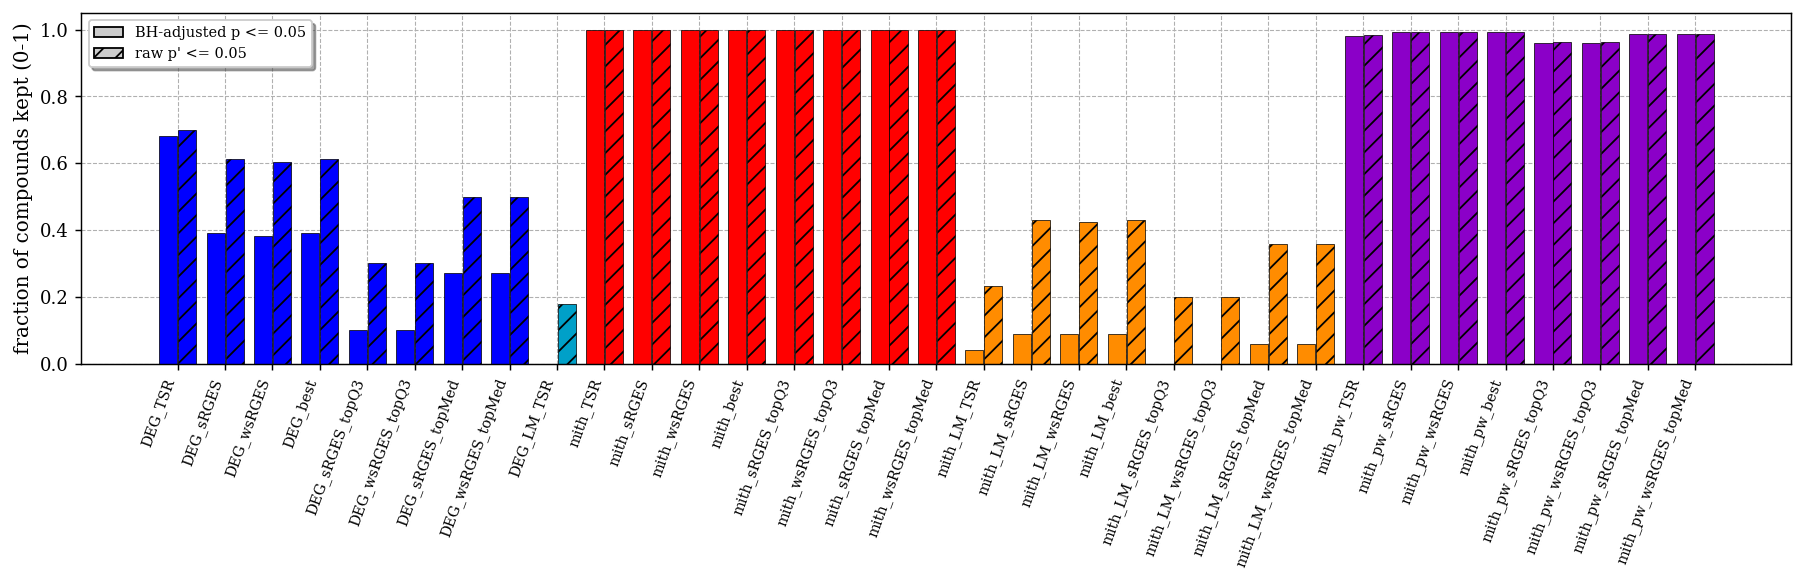

![fraction kept](../imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_fraction_kept.png)

**Figure 2.** Fraction of the compounds of each unfiltered ranking that remain after the filter (0-1); plain bars BH-adjusted p <= 0.05, hatched bars raw p' <= 0.05; colour = configuration.

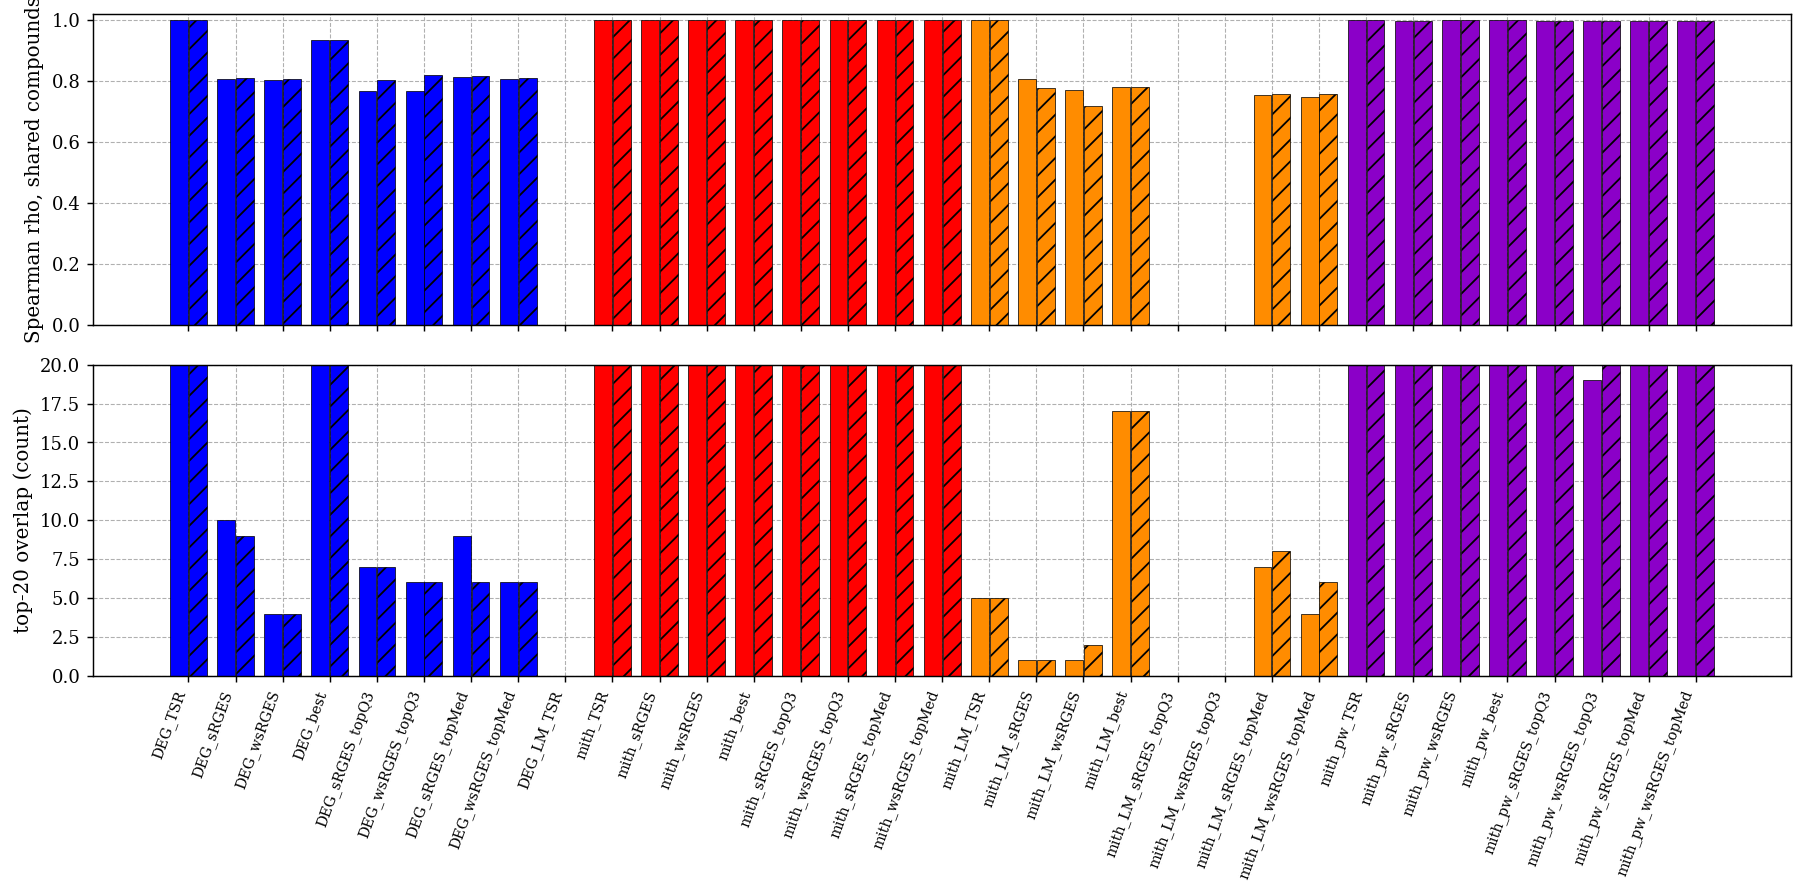

![agreement](../imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_agreement.png)

**Figure 3.** BH filter: agreement between the unfiltered and the filtered ranking. Plain bars: dose/time offsets rebuilt from the surviving instances; hatched bars: offsets frozen at the unfiltered table (equal to plain bars for TSR rankings). Top: Spearman rho of the scores on the compounds present in both (-1 to 1). Bottom: number of compounds (0-20) shared by the 20 most negative scores of the two rankings. Colour = configuration.

In [8]:
order = list(res['rk']['none'])
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(14, 4.6))
for off, m, hatch in [(-.2, 'bh05', None), (.2, 'raw05', '//')]:
    d = summ[summ['filter'] == m].set_index('ranking').loc[order]
    ax.bar(x + off, d['frac_kept'], width=.38, color=[config_colour(res['meta'][n][0]) for n in order], hatch=hatch,
           edgecolor='k', linewidth=.4)
ax.set_xticks(x); ax.set_xticklabels(order, rotation=70, ha='right', fontsize=8)
ax.set_ylabel('fraction of compounds kept (0-1)'); ax.set_ylim(0, 1.05)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='0.8', edgecolor='k', label="BH-adjusted p <= 0.05"), Patch(facecolor='0.8', edgecolor='k', hatch='//', label="raw p' <= 0.05")], fontsize=8)
plt.tight_layout()
f = IMG / f'{SLUG}_cs_pvalue_filter_fraction_kept.png'
fig.savefig(f, dpi=130); plt.close(fig)
display(Image(filename=str(f)))   # inline in the notebook; the Markdown link below serves the exported report
display(Markdown(f"![fraction kept]({REL}/{f.name})\n\n**Figure 2.** Fraction of the compounds of each unfiltered ranking that remain after the filter "
                 "(0-1); plain bars BH-adjusted p <= 0.05, hatched bars raw p' <= 0.05; colour = configuration."))

b = summ[summ['filter'] == 'bh05'].set_index('ranking').loc[order]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
cols = [config_colour(res['meta'][n][0]) for n in order]
bf = summ[summ['filter'] == 'bh05_frozen'].set_index('ranking').loc[order]
axes[0].bar(x - .2, b['spearman'], width=.38, color=cols, edgecolor='k', linewidth=.4); axes[0].bar(x + .2, bf['spearman'], width=.38, color=cols, edgecolor='k', linewidth=.4, hatch='//'); axes[0].set_ylabel('Spearman rho, shared compounds'); axes[0].set_ylim(min(0, np.nanmin(b['spearman']) - .05), 1.02)
axes[1].bar(x - .2, b[f'top{pf.TOP}_overlap'], width=.38, color=cols, edgecolor='k', linewidth=.4); axes[1].bar(x + .2, bf[f'top{pf.TOP}_overlap'], width=.38, color=cols, edgecolor='k', linewidth=.4, hatch='//'); axes[1].set_ylabel(f'top-{pf.TOP} overlap (count)'); axes[1].set_ylim(0, pf.TOP)
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=70, ha='right', fontsize=8)
plt.tight_layout()
f = IMG / f'{SLUG}_cs_pvalue_filter_agreement.png'
fig.savefig(f, dpi=130); plt.close(fig)
display(Image(filename=str(f)))   # inline in the notebook; the Markdown link below serves the exported report
display(Markdown(f"![agreement]({REL}/{f.name})\n\n**Figure 3.** BH filter: agreement between the unfiltered and the filtered ranking. Plain bars: dose/time offsets rebuilt from the surviving instances; hatched bars: offsets frozen at the unfiltered table (equal to plain bars for TSR rankings). Top: Spearman rho of the scores on the compounds "
                 f"present in both (-1 to 1). Bottom: number of compounds (0-{pf.TOP}) shared by the {pf.TOP} most negative scores of the two rankings. Colour = configuration."))

## 4. Known drugs before and after the filter

In [9]:
lab = pd.read_csv(OUT / f'{SLUG}_repodb_labelled_drug_scores.tsv', sep='\t')
lab_drugs = lab.drop_duplicates('drugbank_id')[['drug_name', 'label']]
ALIAS = {'beclometasonedipropionate': ['beclometasone', 'beclomethasonedipropionate'], 'diprophylline': ['dyphylline']}   # name of the label table -> L1000 names
EXCLUDED = ['moxifloxacin']   # label override of this notebook: not a negative (its trial's active comparator was not dosed), so not a known drug
known = {}
for d, l in lab_drugs.values:
    if d in EXCLUDED:
        continue
    k = kd.key([d])[0]
    known[d] = (l, [k] + ALIAS.get(k, []))
DETAIL_CLASSES = ['negative']   # approved drugs are summarised per ranking, the negative is listed individually
KNOWN_TEXT = (f"{sum(v[0] == 'approved' for v in known.values())} approved asthma drugs (positives) and "
              f"{sum(v[0] == 'negative' for v in known.values())} negative (" +
              ", ".join(d for d, v in known.items() if v[0] == 'negative') +
              "; repoDB pair stopped for safety). Label override defined in this notebook: the label table "
              f"`{SLUG}_repodb_labelled_drug_scores.tsv` also marks " + ", ".join(EXCLUDED) +
              " as negative; it is excluded here because its trial's active comparator was not dosed, so the drug is not a negative. "
              "The case-study specification is unchanged")
kn = pd.concat([pf.known_table(res['rk']['none'], res['rk'][m], known, m) for m in ('bh05', 'raw05')], ignore_index=True)
kn.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_known_drugs.tsv', sep='\t', index=False)
display(Markdown(f"Known drugs: {KNOWN_TEXT}. Small n: the numbers below describe where these drugs fall and do not measure how well a ranking works."))

Known drugs: 18 approved asthma drugs (positives) and 1 negative (pioglitazone; repoDB pair stopped for safety). Label override defined in this notebook: the label table `asthma_GSE152004_repodb_labelled_drug_scores.tsv` also marks moxifloxacin as negative; it is excluded here because its trial's active comparator was not dosed, so the drug is not a negative. The case-study specification is unchanged. Small n: the numbers below describe where these drugs fall and do not measure how well a ranking works.

In [10]:
k = kn[(kn['filter'] == 'bh05') & (kn['status'] != 'not scored')]
ag = (k.groupby(['ranking', 'class'], sort=False)
        .apply(lambda d: pd.Series({'n_scored': len(d), 'n_kept': int((d['status'] == 'kept').sum()),
                                    'median_percentile_before_kept': d.loc[d['status'] == 'kept', 'percentile_before'].median(),
                                    'median_percentile_after': d.loc[d['status'] == 'kept', 'percentile_after'].median()}), include_groups=False)
        .reset_index())
ag[['n_scored', 'n_kept']] = ag[['n_scored', 'n_kept']].astype(int)
display(Markdown("**Table 5.** BH filter: known drugs per ranking and class (full table, also for the raw filter: "
                 f"`{SLUG}_cs_pvalue_filter_known_drugs.tsv`). `n_scored`: known drugs scored by the unfiltered ranking (count); `n_kept`: of those, drugs that remain after the filter; "
                 "medians over the kept drugs of the percentile (0-100, low = stronger predicted reversal) in the unfiltered and in the filtered ranking, each within its own universe.\n\n" + pf.md_table(ag, 1)))
d = k if DETAIL_CLASSES is None else k[k['class'].isin(DETAIL_CLASSES)]
dd = d[['ranking', 'drug', 'n_before', 'rank_before', 'percentile_before', 'n_after', 'rank_after', 'percentile_after', 'status']].copy()
for c in ['rank_before', 'rank_after']:
    dd[c] = dd[c].map(lambda v: '' if pd.isna(v) else f'{int(v)}')
display(Markdown("**Table 6.** BH filter: individual known drugs" + ("" if DETAIL_CLASSES is None else " of class " + ", ".join(DETAIL_CLASSES)) +
                 ", one row per ranking. `rank_*`: position in the ranking (1 = most negative score); `n_*`: compounds in the ranking (count); `percentile_*`: 0-100, low = stronger predicted reversal; "
                 "`status`: `kept` / `removed` by the filter.\n\n" + pf.md_table(dd, 1)))

**Table 5.** BH filter: known drugs per ranking and class (full table, also for the raw filter: `asthma_GSE152004_cs_pvalue_filter_known_drugs.tsv`). `n_scored`: known drugs scored by the unfiltered ranking (count); `n_kept`: of those, drugs that remain after the filter; medians over the kept drugs of the percentile (0-100, low = stronger predicted reversal) in the unfiltered and in the filtered ranking, each within its own universe.

| ranking | class | n_scored | n_kept | median_percentile_before_kept | median_percentile_after |
|---|---|---|---|---|---|
| DEG_TSR | approved | 9 | 4 | 79.3 | 69.6 |
| DEG_TSR | negative | 1 | 1 | 29.8 | 43.7 |
| DEG_sRGES | approved | 18 | 8 | 62.3 | 58.6 |
| DEG_sRGES | negative | 1 | 1 | 61.5 | 81.3 |
| DEG_wsRGES | approved | 18 | 8 | 60.0 | 57.1 |
| DEG_wsRGES | negative | 1 | 1 | 60.6 | 87.4 |
| DEG_best | approved | 18 | 8 | 22.6 | 51.4 |
| DEG_best | negative | 1 | 1 | 33.2 | 79.6 |
| DEG_sRGES_topMed | approved | 11 | 3 | 43.4 | 40.7 |
| DEG_wsRGES_topMed | approved | 11 | 3 | 47.3 | 42.2 |
| DEG_LM_TSR | approved | 9 | 0 |  |  |
| DEG_LM_TSR | negative | 1 | 0 |  |  |
| mith_TSR | approved | 9 | 9 | 46.4 | 46.3 |
| mith_TSR | negative | 1 | 1 | 2.1 | 2.1 |
| mith_sRGES | approved | 18 | 18 | 31.5 | 31.6 |
| mith_sRGES | negative | 1 | 1 | 50.0 | 49.9 |
| mith_wsRGES | approved | 18 | 18 | 30.8 | 30.8 |
| mith_wsRGES | negative | 1 | 1 | 55.1 | 55.0 |
| mith_best | approved | 18 | 18 | 16.7 | 16.7 |
| mith_best | negative | 1 | 1 | 23.9 | 23.9 |
| mith_sRGES_topMed | approved | 11 | 11 | 40.6 | 40.6 |
| mith_wsRGES_topMed | approved | 11 | 11 | 40.3 | 40.3 |
| mith_LM_TSR | approved | 9 | 0 |  |  |
| mith_LM_TSR | negative | 1 | 0 |  |  |
| mith_LM_sRGES | approved | 18 | 1 | 49.8 | 44.1 |
| mith_LM_sRGES | negative | 1 | 0 |  |  |
| mith_LM_wsRGES | approved | 18 | 1 | 44.2 | 43.1 |
| mith_LM_wsRGES | negative | 1 | 0 |  |  |
| mith_LM_best | approved | 18 | 1 | 23.5 | 44.8 |
| mith_LM_best | negative | 1 | 0 |  |  |
| mith_LM_sRGES_topMed | approved | 11 | 0 |  |  |
| mith_LM_wsRGES_topMed | approved | 11 | 0 |  |  |
| mith_pw_TSR | approved | 9 | 9 | 72.1 | 71.5 |
| mith_pw_TSR | negative | 1 | 1 | 84.9 | 84.6 |
| mith_pw_sRGES | approved | 18 | 18 | 60.0 | 60.0 |
| mith_pw_sRGES | negative | 1 | 1 | 50.0 | 46.8 |
| mith_pw_wsRGES | approved | 18 | 18 | 58.8 | 58.7 |
| mith_pw_wsRGES | negative | 1 | 1 | 55.1 | 52.9 |
| mith_pw_best | approved | 18 | 18 | 23.0 | 23.1 |
| mith_pw_best | negative | 1 | 1 | 9.0 | 9.1 |
| mith_pw_sRGES_topMed | approved | 11 | 10 | 54.6 | 54.4 |
| mith_pw_wsRGES_topMed | approved | 11 | 10 | 55.6 | 55.4 |

**Table 6.** BH filter: individual known drugs of class negative, one row per ranking. `rank_*`: position in the ranking (1 = most negative score); `n_*`: compounds in the ranking (count); `percentile_*`: 0-100, low = stronger predicted reversal; `status`: `kept` / `removed` by the filter.

| ranking | drug | n_before | rank_before | percentile_before | n_after | rank_after | percentile_after | status |
|---|---|---|---|---|---|---|---|---|
| DEG_TSR | pioglitazone | 3221 | 959 | 29.8 | 2195 | 959 | 43.7 | kept |
| DEG_sRGES | pioglitazone | 12440 | 7646 | 61.5 | 4879 | 3965 | 81.3 | kept |
| DEG_wsRGES | pioglitazone | 12419 | 7524 | 60.6 | 4763 | 4165 | 87.4 | kept |
| DEG_best | pioglitazone | 12440 | 4134 | 33.2 | 4879 | 3884 | 79.6 | kept |
| DEG_LM_TSR | pioglitazone | 3221 | 2315 | 71.9 | 0 |  |  | removed |
| mith_TSR | pioglitazone | 3221 | 67 | 2.1 | 3215 | 67 | 2.1 | kept |
| mith_sRGES | pioglitazone | 12440 | 6215 | 50.0 | 12429 | 6205 | 49.9 | kept |
| mith_wsRGES | pioglitazone | 12419 | 6839 | 55.1 | 12407 | 6823 | 55.0 | kept |
| mith_best | pioglitazone | 12440 | 2970 | 23.9 | 12429 | 2970 | 23.9 | kept |
| mith_LM_TSR | pioglitazone | 3221 | 658 | 20.4 | 131 |  |  | removed |
| mith_LM_sRGES | pioglitazone | 12440 | 6289 | 50.6 | 1126 |  |  | removed |
| mith_LM_wsRGES | pioglitazone | 12419 | 5728 | 46.1 | 1115 |  |  | removed |
| mith_LM_best | pioglitazone | 12440 | 5422 | 43.6 | 1126 |  |  | removed |
| mith_pw_TSR | pioglitazone | 3221 | 2734 | 84.9 | 3163 | 2676 | 84.6 | kept |
| mith_pw_sRGES | pioglitazone | 12440 | 6219 | 50.0 | 12350 | 5781 | 46.8 | kept |
| mith_pw_wsRGES | pioglitazone | 12419 | 6842 | 55.1 | 12329 | 6517 | 52.9 | kept |
| mith_pw_best | pioglitazone | 12440 | 1122 | 9.0 | 12350 | 1122 | 9.1 | kept |

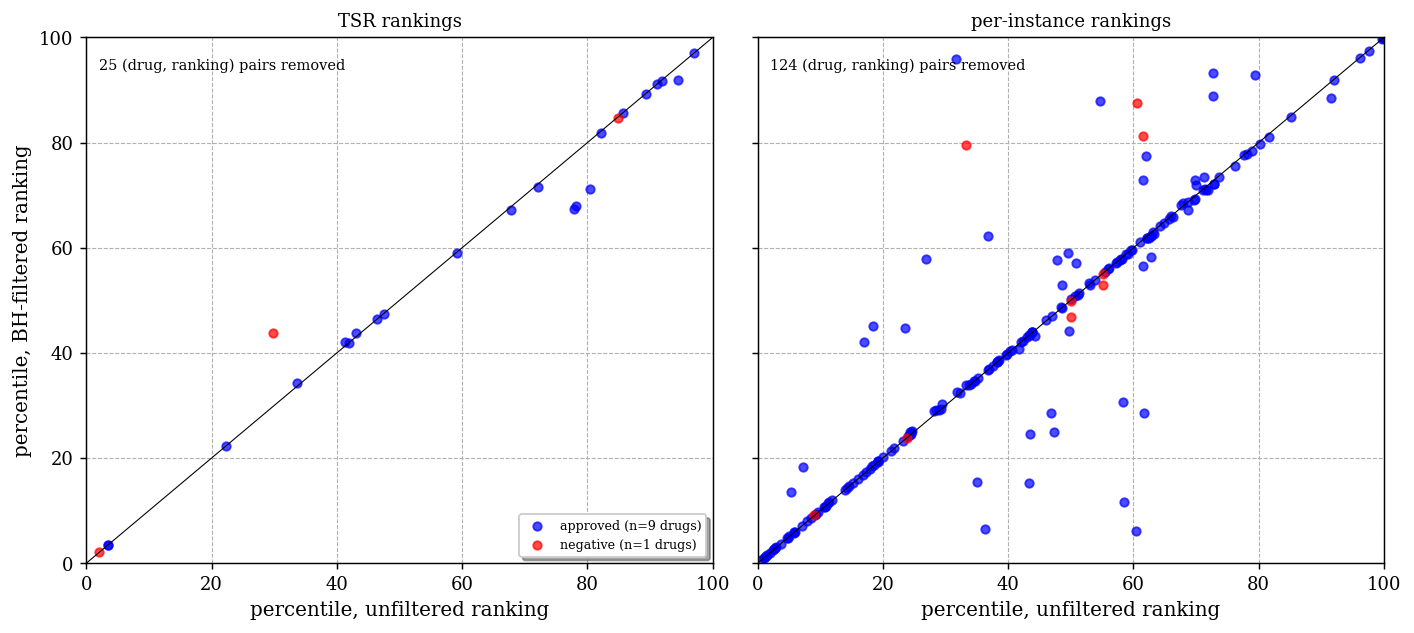

![known drugs](../imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_known_drugs.png)

**Figure 4.** Known drugs kept by the BH filter: percentile (0-100, low = stronger predicted reversal) in the unfiltered ranking against the filtered one, one point per (drug, ranking); left TSR rankings, right per-instance rankings; the diagonal marks no change; removed pairs are counted in each panel.

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
classes = sorted(k['class'].unique())
classes = sorted(k['class'].unique())
cmap = dict(zip(classes, ['#0000FF', '#FF0000', '#008000', '#FF8C00', '#8B00C8', '0.3']))
for ax, (title, sel) in zip(axes, [('TSR rankings', k['ranking'].isin(tsr_names)), ('per-instance rankings', ~k['ranking'].isin(tsr_names))]):
    d = k[sel & (k['status'] == 'kept')]
    for c in classes:
        e = d[d['class'] == c]
        ax.scatter(e['percentile_before'], e['percentile_after'], s=22, alpha=.7, color=cmap[c], label=f'{c} (n={e["drug"].nunique()} drugs)')
    ax.plot([0, 100], [0, 100], color='k', lw=.6); ax.set_title(title, fontsize=10)
    ax.set_xlabel('percentile, unfiltered ranking'); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    nrem = int(((k['status'] == 'removed') & sel).sum()); ax.text(.02, .96, f'{nrem} (drug, ranking) pairs removed', transform=ax.transAxes, fontsize=8, va='top')
axes[0].set_ylabel('percentile, BH-filtered ranking'); axes[0].legend(fontsize=7, loc='lower right')
plt.tight_layout()
f = IMG / f'{SLUG}_cs_pvalue_filter_known_drugs.png'
fig.savefig(f, dpi=130); plt.close(fig)
display(Image(filename=str(f)))   # inline in the notebook; the Markdown link below serves the exported report
display(Markdown(f"![known drugs]({REL}/{f.name})\n\n**Figure 4.** Known drugs kept by the BH filter: percentile (0-100, low = stronger predicted reversal) in the unfiltered "
                 "ranking against the filtered one, one point per (drug, ranking); left TSR rankings, right per-instance rankings; the diagonal marks no change; removed pairs are counted in each panel."))

## 5. Recomputation check

In [12]:
# (a) per-drug scores of the unfiltered recomputation vs the stored step-'srges' table
st = pd.read_csv(OUT / f'{SLUG}_srges_per_drug.tsv', sep='\t')
new = res['tables']['none']
j = new.merge(st, on=['config', 'collapse', 'pert_iname'], how='outer', suffixes=('_new', '_old'), indicator=True)
rows = []
for c in ['score', 'n_instances', 'n_cell_lines', 'n_pert_ids']:
    both = j['_merge'] == 'both'
    x, y = j.loc[both, f'{c}_new'].astype(float), j.loc[both, f'{c}_old'].astype(float)
    rows.append({'check': f'{SLUG}_srges_per_drug.tsv, column {c}', 'n_compared': int(x.notna().sum()),
                 'n_unmatched': int((j['_merge'] != 'both').sum()), 'max_abs_diff': float((x - y).abs().max()),
                 'pass': bool((x - y).abs().max() <= TOL and (j['_merge'] == 'both').all())})
chk = [pd.DataFrame(rows)]
# (b) long ranking table vs the stored drug rankings
fn = OUT / f'{SLUG}_drug_rankings.tsv'
if fn.exists():
    stored = pd.read_csv(fn, sep='\t', low_memory=False)
    r, oa, ob = pf.sanity(res['long']['none'], stored, TOL)
    chk.append(r.assign(check=lambda d: f'{fn.name}, column ' + d['column'], n_unmatched=oa + ob)
                 [['check', 'n_compared', 'n_unmatched', 'max_abs_diff', 'n_diff_above_tol', 'n_diff_not_near_tie', 'pass']])
    tsr_ids = stored[stored['ranking'].str.endswith('_TSR')].groupby('ranking')['cs_run_id'].first()
    ln = res['long']['none']
    now = ln[ln['ranking'].str.endswith('_TSR')].groupby('ranking')['cs_run_id'].first()
    chk.append(pd.DataFrame([{'check': f'{fn.name}, TSR run IDs', 'n_compared': len(tsr_ids), 'n_unmatched': int((tsr_ids != now.reindex(tsr_ids.index)).sum()),
                              'max_abs_diff': np.nan, 'pass': bool((tsr_ids == now.reindex(tsr_ids.index)).all())}]))
# (c) labelled-drug scores of the repoDB step against the recomputed unfiltered rankings
REN = {'sRGES_unweighted': 'sRGES', 'sRGES_weighted': 'wsRGES', 'best': 'best',
       'sRGES_unweighted_top_median': 'sRGES_topMed', 'sRGES_weighted_top_median': 'wsRGES_topMed'}
L = lab.assign(ranking=lambda d: np.where(d['route'] == 'tsr_lmm_collapsed', d['config'] + '_TSR',
                                          d['config'] + '_' + d['collapse'].map(REN)))
L = L[L['ranking'].isin(res['rk']['none']) & L['drug_name'].isin(known)].dropna(subset=['score'])
n_pooled = int((L['n_names'] > 1).sum())   # labelled drugs whose repoDB score pools several L1000 names (not one ranking entry)
L = L[L['n_names'] == 1]
diffs = []
for _, r in L.iterrows():
    keys = known[r['drug_name']][1]
    h = res['rk']['none'][r['ranking']]
    h = h[h['drug_key'].isin(keys)]
    diffs.append(abs(h['score'].iloc[0] - r['score']) if len(h) == 1 else np.nan)
L = L.assign(abs_diff=diffs)
chk_c = pd.DataFrame([{'check': f'labelled-drug scores of the repoDB step vs recomputed rankings (single-name drugs; {n_pooled} (drug, ranking) scores pooling several L1000 names excluded)', 'n_compared': int(L['abs_diff'].notna().sum()),
                       'n_unmatched': int(L['abs_diff'].isna().sum()), 'max_abs_diff': L['abs_diff'].max(),
                       'pass': bool(L['abs_diff'].notna().all() and L['abs_diff'].max() <= TOL)}])
chk.append(pd.DataFrame([{'check': f"frozen offsets on all instances vs unfiltered scores, {r_.config}", 'n_compared': r_.n_compared, 'n_unmatched': 0, 'max_abs_diff': r_.max_abs_diff, 'pass': bool(r_.max_abs_diff <= TOL)} for r_ in res['frozen_check'].itertuples()]))
chk.append(chk_c)
chk = pd.concat(chk, ignore_index=True)
chk.to_csv(OUT / f'{SLUG}_cs_pvalue_filter_recomputation_check.tsv', sep='\t', index=False)
display(Markdown(f"**Table 7.** Recomputation check: the unfiltered rankings rebuilt by this notebook against the tables written by the case-study pipeline "
                 f"(`{SLUG}_cs_pvalue_filter_recomputation_check.tsv`). `n_compared`: values compared (count); `n_unmatched`: rows present in only one table; `max_abs_diff`: largest absolute difference "
                 f"(score in CS units; ranks in positions; percentiles in percentile points); `n_diff_above_tol`: differences above {TOL:g}; `n_diff_not_near_tie`: those not explained by a near-tie "
                 f"(two compounds whose scores differ by at most {TOL:g}, so that their order depends on floating-point rounding); `pass`: all differences within tolerance or on near-ties.\n\n" + pf.md_table(chk, 3)))
display(Markdown(f"**All checks pass: {bool(chk['pass'].all())}.**"))

**Table 7.** Recomputation check: the unfiltered rankings rebuilt by this notebook against the tables written by the case-study pipeline (`asthma_GSE152004_cs_pvalue_filter_recomputation_check.tsv`). `n_compared`: values compared (count); `n_unmatched`: rows present in only one table; `max_abs_diff`: largest absolute difference (score in CS units; ranks in positions; percentiles in percentile points); `n_diff_above_tol`: differences above 1e-12; `n_diff_not_near_tie`: those not explained by a near-tie (two compounds whose scores differ by at most 1e-12, so that their order depends on floating-point rounding); `pass`: all differences within tolerance or on near-ties.

| check | n_compared | n_unmatched | max_abs_diff | pass |
|---|---|---|---|---|
| asthma_GSE152004_srges_per_drug.tsv, column score | 192020 | 0 | 1.00e-16 | True |
| asthma_GSE152004_srges_per_drug.tsv, column n_instances | 192020 | 0 | 0.000 | True |
| asthma_GSE152004_srges_per_drug.tsv, column n_cell_lines | 192020 | 0 | 0.000 | True |
| asthma_GSE152004_srges_per_drug.tsv, column n_pert_ids | 192020 | 0 | 0.000 | True |
| frozen offsets on all instances vs unfiltered scores, DEG | 48005 | 0 | 0.000 | True |
| frozen offsets on all instances vs unfiltered scores, mith | 48005 | 0 | 0.000 | True |
| frozen offsets on all instances vs unfiltered scores, mith_LM | 48005 | 0 | 0.000 | True |
| frozen offsets on all instances vs unfiltered scores, mith_pw | 48005 | 0 | 0.000 | True |
| labelled-drug scores of the repoDB step vs recomputed rankings (single-name drugs; 12 (drug, ranking) scores pooling several L1000 names excluded) | 304 | 0 | 9.89e-17 | True |

**All checks pass: True.**

## 6. Outputs

In [13]:
tidy = res['long']['bh05']
tidy.to_csv(OUT / f'{SLUG}_drug_rankings_pvalue_filtered.tsv', sep='\t', index=False)
if chg['abs_diff_spearman_variants'].max() > 0.05:
    res['long']['bh05f'].to_csv(OUT / f'{SLUG}_drug_rankings_pvalue_filtered_frozen_offsets.tsv', sep='\t', index=False)
files = sorted(OUT.glob(f'{SLUG}_cs_pvalue_filter_*')) + [OUT / f'{SLUG}_drug_rankings_pvalue_filtered.tsv'] + sorted(OUT.glob(f'{SLUG}_drug_rankings_pvalue_filtered_frozen*')) + sorted(IMG.glob(f'{SLUG}_cs_pvalue_filter_*'))
display(Markdown(f"Filtered rankings (BH-adjusted p <= 0.05) of every ranking, same columns as `{SLUG}_drug_rankings.tsv` "
                 f"(`ranking`, `config`, `collapse`, `drug_key`, `drug`, `score`, `rank`, `percentile`, `percentile_shared_DEG`, `n_instances`, `n_cell_lines`, `stratum`, `n_drugs_stratum`, `percentile_stratum`, `cs_run_id`): "
                 f"{len(tidy):,} rows, {tidy['ranking'].nunique()} rankings; rank and percentiles are computed within the filtered universe, `percentile_shared_DEG` over the compounds scored by both filtered `DEG_TSR` and `DEG_sRGES`, "
                 f"`n_instances` counts the surviving instances.\n\n**Files:**\n\n" + "\n".join(f"- `{str(p.relative_to(ROOT))}`" for p in files)))

Filtered rankings (BH-adjusted p <= 0.05) of every ranking, same columns as `asthma_GSE152004_drug_rankings.tsv` (`ranking`, `config`, `collapse`, `drug_key`, `drug`, `score`, `rank`, `percentile`, `percentile_shared_DEG`, `n_instances`, `n_cell_lines`, `stratum`, `n_drugs_stratum`, `percentile_stratum`, `cs_run_id`): 125,570 rows, 30 rankings; rank and percentiles are computed within the filtered universe, `percentile_shared_DEG` over the compounds scored by both filtered `DEG_TSR` and `DEG_sRGES`, `n_instances` counts the surviving instances.

**Files:**

- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_cell_lines.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_instances_kept.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_known_drugs.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_offset_variants.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_recomputation_check.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_resolution.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_runs.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_sign_split.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_summary.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_drug_rankings_pvalue_filtered.tsv`
- `other_outputs/case_studies/asthma_GSE152004/asthma_GSE152004_drug_rankings_pvalue_filtered_frozen_offsets.tsv`
- `imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_agreement.png`
- `imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_fraction_kept.png`
- `imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_known_drugs.png`
- `imgs/case_studies/asthma_GSE152004/asthma_GSE152004_cs_pvalue_filter_pvalue_distribution.png`